In [1]:
import sys

sys.path.append('../..')
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pydicom import dcmread
import os
import random
from natsort import natsorted, index_natsorted
import glob

from PIL import Image
import time
import copy
import tqdm
import re
import shutil
# import cv2

from sklearn.cluster import KMeans, DBSCAN

import warnings
warnings.filterwarnings("ignore")

In [2]:
home_path = os.path.expanduser('~/')
images_path = f'/data/deep_tee/first_transfer'

In [3]:
subject_list = []
for subject in tqdm.tqdm(natsorted(glob.glob(images_path + '/*/'))):
    dicom_list = []
    for dicom in natsorted(glob.glob(subject + '/*.dcm')):
        dicom_list.append(dicom)
    subject_list.append(dicom_list)

100%|██████████| 6900/6900 [00:18<00:00, 369.79it/s]


In [11]:
def derive_time(dicom):
    dcm = dcmread(dicom)
    if 'PixelData' not in dcm:
        return -1
    if 'ContentTime' in dcm:
        hour = int(dcm.ContentTime[0:2])
        minute = int(dcm.ContentTime[2:4])
        second = int(dcm.ContentTime[4:6])
    elif 'AcquisitionDateTime' in dcm: 
        hour = int(dcm.AcquisitionDateTime[8:10])
        minute = int(dcm.AcquisitionDateTime[10:12])
        second = int(dcm.AcquisitionDateTime[12:14])
    return (hour*3600 + minute*60 + second)/3600

def get_subject_times(subject):
    acq_times = []
    for dicom in subject:
        try:
            acq_times.append((derive_time(dicom),dicom))
        except:
            print(f'failed on {dicom}')
            acq_times.append([0, subject])
    earliest = acq_times[0][0]
    acq_times = [(-1, time[1]) if time[0] == -1 else (time[0]-earliest, time[1]) for time in acq_times]
    acq_times = [(-1, time[1] if time[0] == -1 else time[0]+3600*24, time[1]) if time[0] < 0 else (time[0], time[1]) for time in acq_times]
    return acq_times

def prepost_op_kmeans(subject_times, distinction_width=0.2, inclusion_width=0.5):
    times = np.array([time[0] for time in subject_times if time[0] != -1]).reshape(-1,1)
    if times.shape[0] < 2:
        return pd.DataFrame(list(zip([s[1] for s in subject_times], [s[0] for s in subject_times], [0 for s in subject_times])), columns = ['clip_path','time','prepost_pred'])
    kmeans = KMeans(n_clusters=2, init=np.array([[0,],[15,]])).fit(times)
    if kmeans.labels_[0] == 1:
        kmeans.labels_ = [-label+1 for label in kmeans.labels_]
                
    centroids = sorted(kmeans.cluster_centers_)
            
    # if centroids are not sufficiently distinct
    if centroids[1]-centroids[0] < distinction_width:
        kmeans.labels_ = [0 for label in kmeans.labels_]
    else:
        # centroid based outlier removal
        intraop_zone = [((centroids[1]+centroids[0])/2)-((centroids[1]-centroids[0])*inclusion_width*0.5), ((centroids[1]+centroids[0])/2)+((centroids[1]-centroids[0])*inclusion_width*0.5)]
        for i,time in enumerate(times):
            if time > intraop_zone[0] and time < intraop_zone[1]:
                kmeans.labels_[i] = -1
                
    final_labels = []
    skipcount = 0
    for i,time in enumerate(subject_times):
        if time[0] == -1:
            final_labels.append(-1)
            skipcount += 1
        else:
            final_labels.append(kmeans.labels_[i - skipcount])
                        
    labeled = pd.DataFrame(list(zip([s[1] for s in subject_times], [s[0] for s in subject_times], final_labels)), columns = ['clip_path','time','prepost_pred'])
    return labeled

def process_and_save(subject, save=True, savepath='/home/trevor/repos/deep_TEE/tasks/pre_post_prediction/predictions'):
    subject_id = os.path.split(os.path.split(subject[0])[0])[1]
    result = prepost_op_kmeans(get_subject_times(subject))
    if save:
        result.to_csv(f'{savepath}/prepost_pred_{subject_id}.csv', header=True)
    else:
        return result

In [12]:
subject = process_and_save(subject_list[1500], save=False)


In [13]:
np.unique(np.array(subject['prepost_pred']))

array([0, 1], dtype=int32)

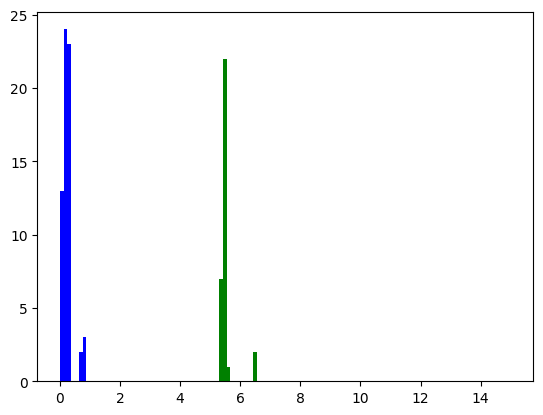

In [14]:
plt.hist(list(subject.loc[subject['prepost_pred'] == 0]['time']), bins=np.linspace(0, 15, 120), label='pre op', color='b')
plt.hist(list(subject.loc[subject['prepost_pred'] == 1]['time']), bins=np.linspace(0, 15, 120), label='post op', color='g')
plt.hist(list(subject.loc[subject['prepost_pred'] ==-1]['time']), bins=np.linspace(0, 15, 120), label='intra op', color='r')
plt.show()

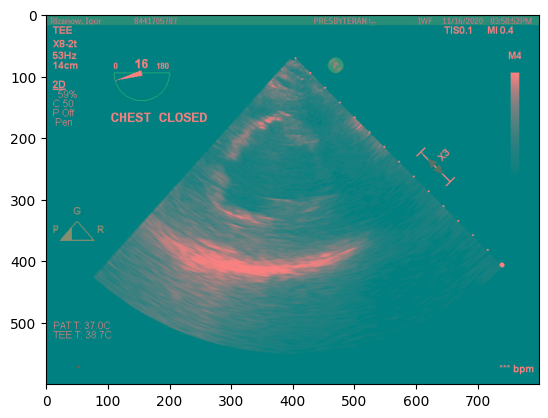

In [15]:
plt.imshow(dcmread(subject.iloc[-1]['clip_path']).pixel_array[0,:,:,:])

In [16]:
for subject in tqdm.tqdm(subject_list):
    process_and_save(subject)

100%|██████████| 6900/6900 [1:53:58<00:00,  1.01it/s]  


In [ ]:
assert False

import multiprocessing

with multiprocessing.Pool(12) as pool:
    pool.map(process_and_save, tqdm.tqdm(subject_list))

 29%|██▉       | 2015/6900 [32:20<1:18:24,  1.04it/s]


KeyboardInterrupt: 

138it [00:12, 11.30it/s]


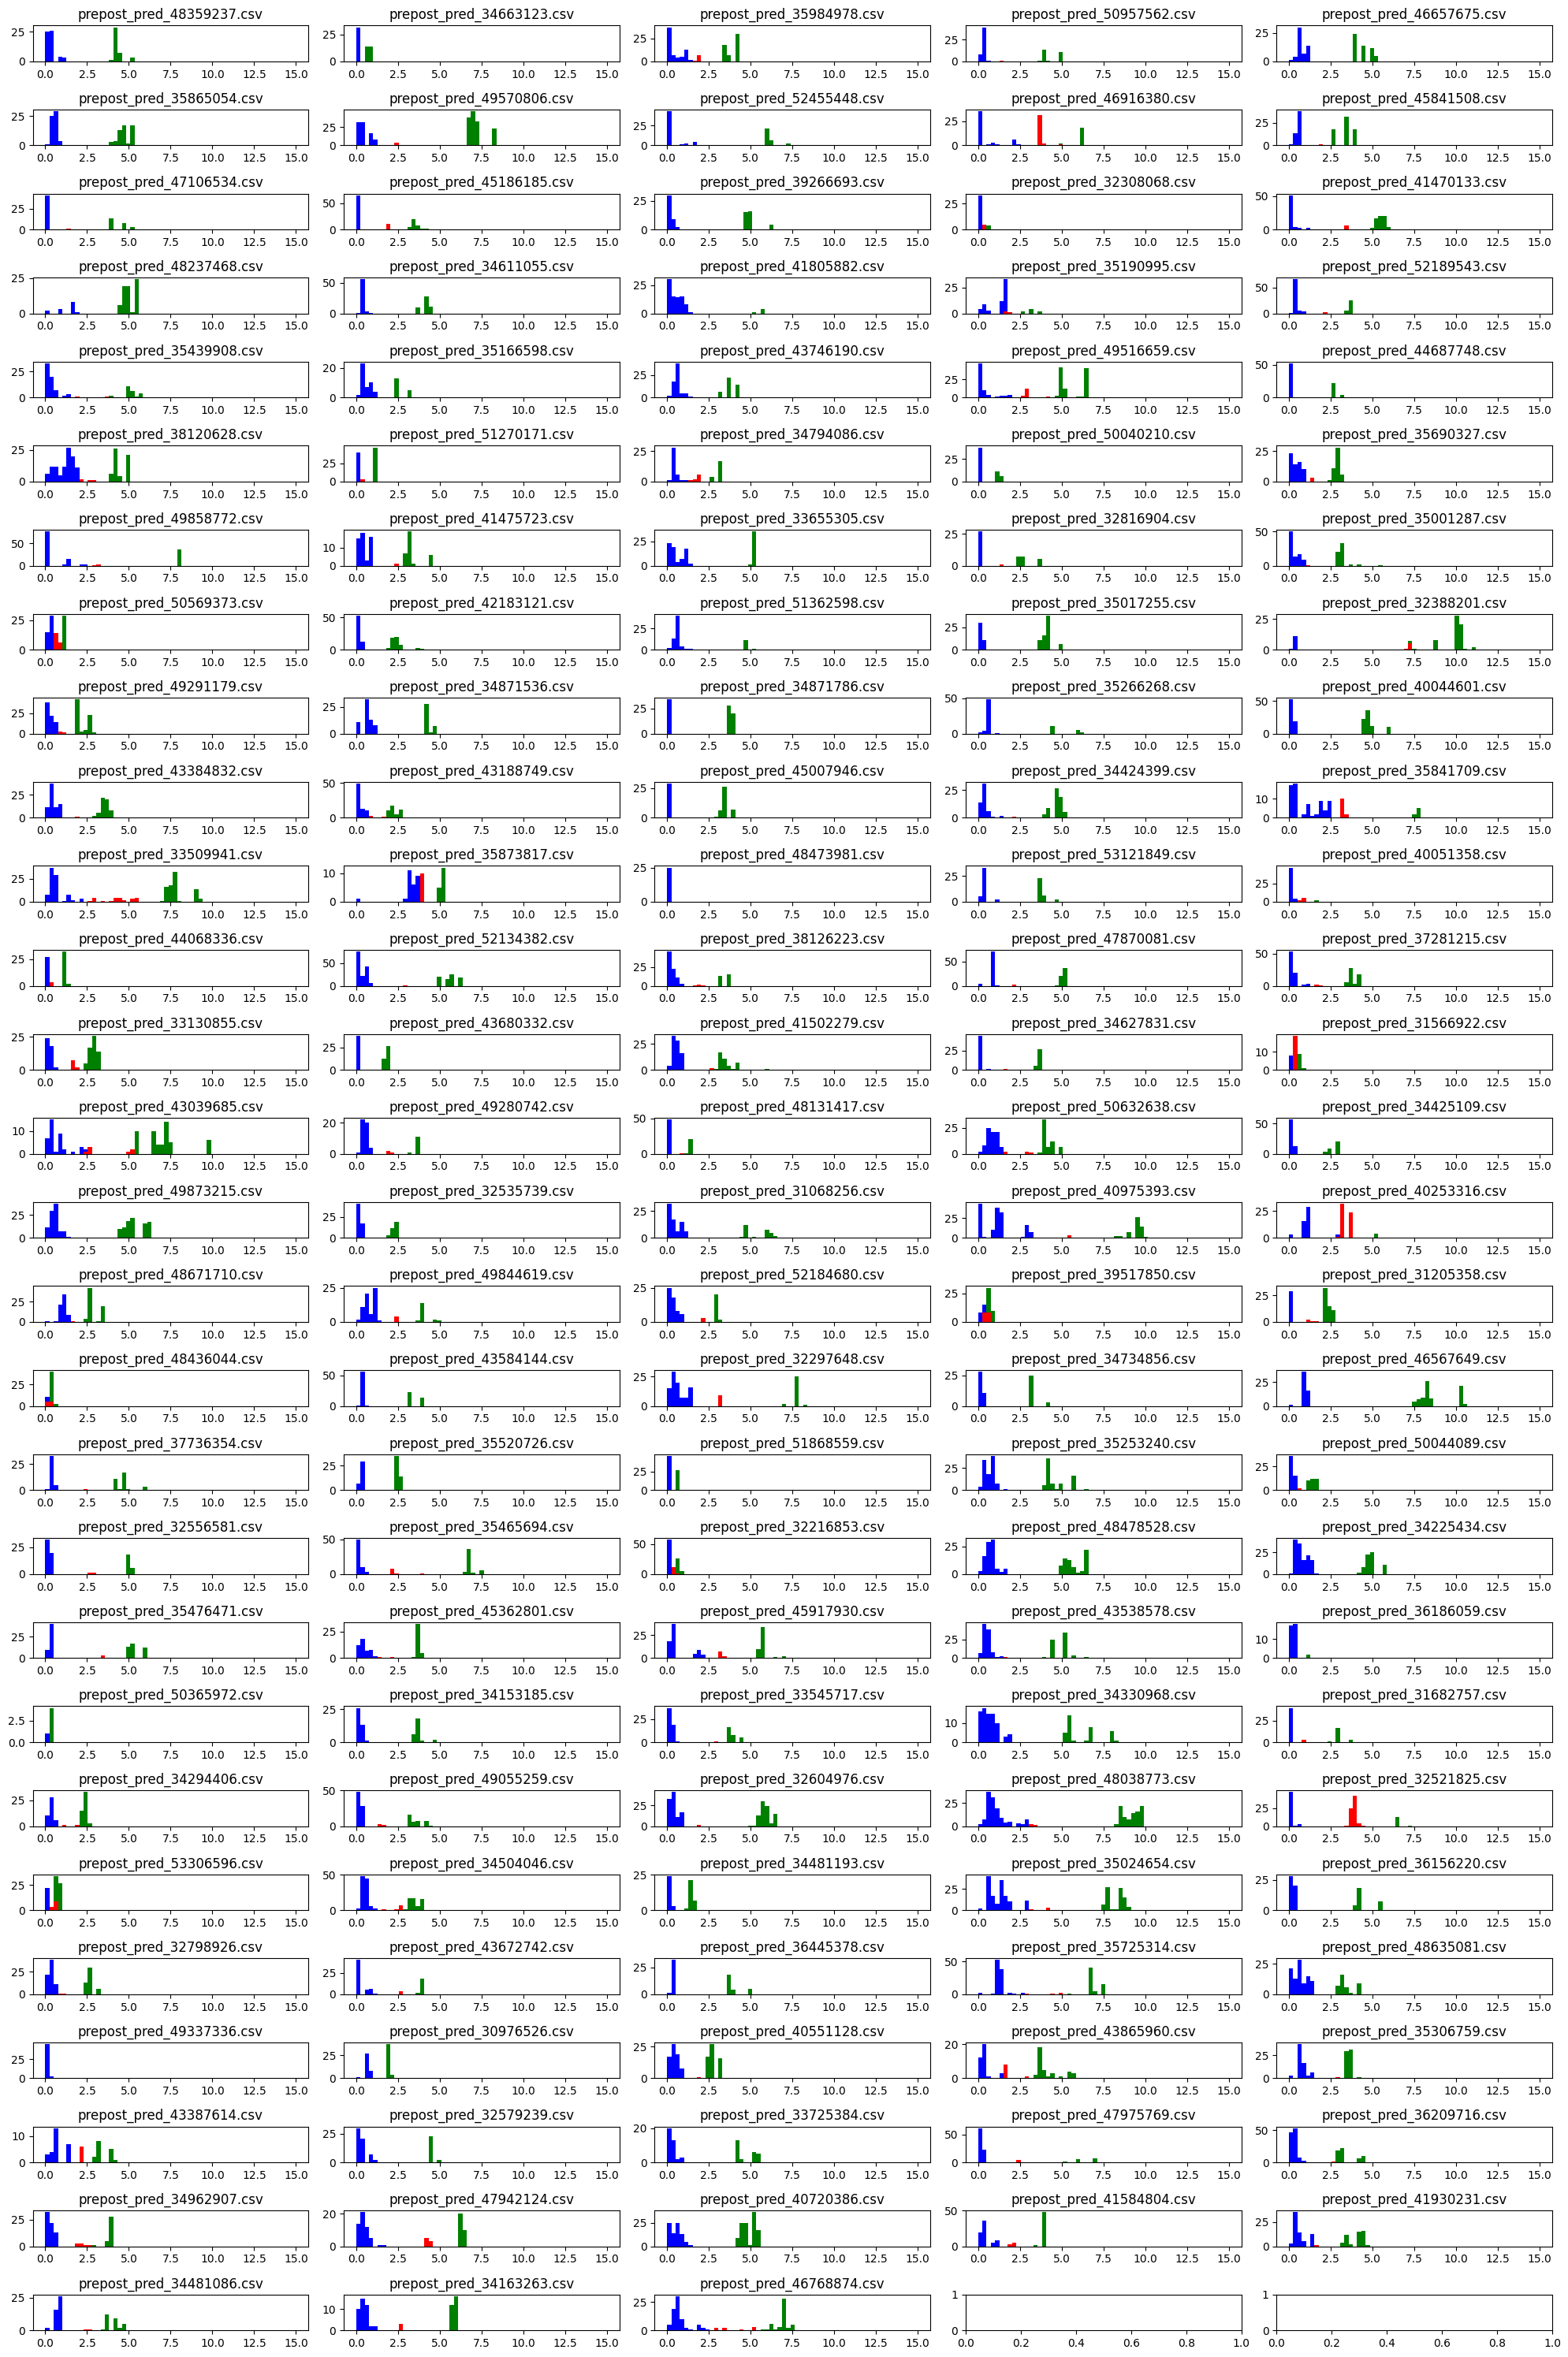

In [17]:
# Plotting for checking
cols = 5
fig, ax = plt.subplots(28, cols, tight_layout=True, figsize=(20, 30))
for i, subject_csv in tqdm.tqdm(enumerate(glob.glob('./predictions/*.csv')[::50])):
    subject = pd.read_csv(subject_csv)
    ax[int(i/cols)][i%cols].hist(list(subject.loc[subject['prepost_pred'] == 0]['time']), bins=np.linspace(0, 15, 60), label='pre op', color='b')
    ax[int(i/cols)][i%cols].hist(list(subject.loc[subject['prepost_pred'] == 1]['time']), bins=np.linspace(0, 15, 60), label='post op', color='g')
    ax[int(i/cols)][i%cols].hist(list(subject.loc[subject['prepost_pred'] ==-1]['time']), bins=np.linspace(0, 15, 60), label='intra op', color='r')
    ax[int(i/cols)][i%cols].set_title(os.path.split(subject_csv)[1])
# plt.show()
plt.savefig('time_clustering.png',format='png',dpi=300)

In [19]:
csvs = './predictions'
csvs = sorted(glob.glob(csvs + '/*.csv'))

In [23]:
df_list = []
for csv in tqdm.tqdm(csvs):
    df_list.append(pd.read_csv(csv))

100%|██████████| 6900/6900 [00:06<00:00, 1074.46it/s]


In [28]:
prepostop = pd.concat(df_list)
prepostop = prepostop.reset_index().drop(columns=['index', 'Unnamed: 0'])

pd.options.mode.chained_assignment = None

for i in tqdm.tqdm(range(len(prepostop))):
    prepostop['clip_path'][i] = prepostop['clip_path'][i][30:]

100%|██████████| 734195/734195 [01:22<00:00, 8906.14it/s]


In [29]:
prepostop

,clip_path,time,prepost_pred
0,30883033/1.2.840.113663.1500.1.434034858.3.2.2...,0.000000,0
1,30883033/1.2.840.113663.1500.1.434034858.3.3.2...,0.004167,0
2,30883033/1.2.840.113663.1500.1.434034858.3.4.2...,0.006944,0
3,30883033/1.2.840.113663.1500.1.434034858.3.5.2...,0.014444,0
4,30883033/1.2.840.113663.1500.1.434034858.3.6.2...,0.016944,0
...,...,...,...
734190,Undefined/1.2.840.113663.1500.1.458671065.3.90...,5.561944,1
734191,Undefined/1.2.840.113663.1500.1.458671065.3.91...,5.565278,1
734192,Undefined/1.2.840.113663.1500.1.458671065.3.92...,5.576111,1
734193,Undefined/1.2.840.113663.1500.1.458671065.3.93...,6.440000,1


In [30]:
prepostop.to_csv('../../labels/preop_postop_prediction.csv')

# Save images to tasks for CVAT labeling

In [ ]:
# Takes the already existing png files from a single folder and sorts them into individual folders based on subject and clip

directory = f'../data/multiview/train/me_4_ch'

subject_pattern = r'^([^_]+)'
clip_pattern = r'^[^_]+_([^_]+)'
frame_pattern = r'^[^_]+_[^_]+_([^\.]+)'

currsub = ''
currclip = ''

savedir = '../data/cvat'
if os.path.exists(savedir):
    shutil.rmtree(savedir)
os.makedirs(savedir)

for impath in tqdm(natsorted(glob.glob(f'{directory}/*.png'))):
    subject = re.match(subject_pattern, os.path.basename(impath)).group()
    clip = re.match(clip_pattern, os.path.basename(impath)).group()
    frame = re.match(frame_pattern, os.path.basename(impath)).group()
    if currsub != subject:
        currsub = subject
        os.makedirs(f'{savedir}/{currsub}')
    if currclip != clip:
        currclip = clip
        os.makedirs(f'{savedir}/{currsub}/{currclip}')
    savepath = f'{savedir}/{currsub}/{currclip}/{frame}.png'

    shutil.copyfile(impath, savepath)

In [ ]:
# Saves the video files for batch upload to CVAT

directory = '../data/cvat'

for subject in tqdm(natsorted(glob.glob(f'{directory}/*'))):
    for clip in natsorted(glob.glob(f'{subject}/*/')):
        images = [img for img in natsorted(glob.glob(f'{clip}*')) if img.endswith(".png")]
        frame = cv2.imread(images[0])
        height, width, layers = frame.shape

        video = cv2.VideoWriter(f'{clip[:-1]}.avi', cv2.VideoWriter_fourcc(*'XVID'), 30, (width,height))

        for image in images:
            video.write(cv2.imread(image))
        cv2.destroyAllWindows()
        video.release()